##Trabajo Proyecto 1 - Emanuel Gallego - Alejandro Jaramillo - Miguel Angel


#El Espejismo del Descuento: ¿Las grandes rebajas maximizan las ventas o sólo erosionan la rentabilidad?

###El Contexto del Problema: En el ecosistema hipercompetitivo del comercio electrónico, la guerra de precios suele ser la norma. Para lograr visibilidad y destacar en plataformas masivas, la estrategia instintiva de muchos vendedores es sacrificar su margen de ganancia aplicando descuentos agresivos. Sin embargo, esta táctica plantea un riesgo financiero crítico: reducir el precio de un artículo no siempre garantiza un aumento proporcional en la demanda ni justifica la pérdida de ingresos por unidad.

###Objetivo del Análisis: Este proyecto busca evaluar empíricamente la verdadera eficiencia de las estrategias promocionales. A través del análisis de datos transaccionales, el objetivo es descubrir en qué escenarios específicos una rebaja actúa como el catalizador definitivo para posicionar un artículo como un éxito masivo de ventas, y en qué casos resulta ser una pérdida innecesaria de rentabilidad frente a consumidores que toman decisiones de compra basados en otros factores, como la prueba social (calificaciones) o la conveniencia.

###Impacto y Valor Comercial: Los hallazgos de este análisis proporcionan una brújula estratégica para la toma de decisiones ejecutivas. El modelo permitirá a los equipos comerciales abandonar las rebajas basadas en la intuición y comenzar a diseñar estrategias de pricing fundamentadas en datos, asegurando que cada descuento aplicado genere un retorno real de inversión y proteja la salud financiera del negocio.


Bibliotecas

In [ ]:
import pandas as pd
import gdown
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
from sklearn.impute import SimpleImputer, KNNImputer, MissingIndicator
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report

##Limpieza de la base de datos

In [ ]:
url = "https://drive.google.com/uc?id=1He7V87bt3K_2yClETl6fAXaaX_0cSUTc"

gdown.download(url, '20240121_shopee_sample_data (1)', quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1He7V87bt3K_2yClETl6fAXaaX_0cSUTc
To: /content/20240121_shopee_sample_data (1)
100%|██████████| 37.7M/37.7M [00:00<00:00, 70.7MB/s]


'20240121_shopee_sample_data (1)'

In [ ]:
from os import read
df = pd.read_csv("20240121_shopee_sample_data (1)")

In [ ]:
df.head()

,price_ori,delivery,item_category_detail,specification,title,w_date,link_ori,item_rating,seller_name,idElastic,price_actual,sitename,idHash,total_rating,id,total_sold,pict_link,favorite,timestamp,desc
0,25.80,"KL City, Kuala Lumpur",Shopee | Women's Bags | Shoulder Bags | Should...,Product Specifications Category Shopee Women's...,1081 PU SLING BAG KULIT leather Casual Beg Tan...,2023-04-27,https://shopee.com.my/1081-PU-SLING-BAG-KULIT-...,4.9,qqfwholesale,19ec9fdedd9fe3e14bc652950fc3c423,12.90,shopee,88f051f0a2dcf0d29191e0175b828938,179,88f051f0a2dcf0d29191e0175b828938,179,https://down-my.img.susercontent.com/file/my-1...,Favorite (128,1682553600000,🎉 WELCOME To QQF WHOLESALE \r\n😍 ALL item read...
1,1.41,NaN,Shopee | Home Appliances | Sewing Machines | S...,Product Specifications Category Shopee Home Ap...,Stat Chinese Traditional Frog Buttons Knot Che...,2023-04-27,https://shopee.com.my/Stat-Chinese-Traditional...,5.0,stationery.my,5322309be3b6d9c01d15fa19f5b7ad9a,0.75,shopee,472d22f58af3bb35cf28c6eed7088dc5,17,472d22f58af3bb35cf28c6eed7088dc5,17,https://down-my.img.susercontent.com/file/4147...,Favorite (19,1682553600000,Chinese Traditional Frog Buttons Knot Cheongsa...
2,8.50,"KL City, Kuala Lumpur",Shopee | Women's Bags | Handbags | Set Handbags,Product Specifications Category Shopee Women's...,N09 READY STOCK MYFOOYIN woman handbag set 2in...,2023-04-26,https://shopee.com.my/N09-READY-STOCK-MYFOOYIN...,4.9,fooyin88,7a36765d1e2ca2b6a5414ddfeedfefc3,8.50,shopee,ec6ce64f4b77efb38b6392818959f181,8.1k,ec6ce64f4b77efb38b6392818959f181,8.1k,https://down-my.img.susercontent.com/file/23da...,Favorite (21.5k,1682467200000,READY STOCK\nMEASUREMENT:\nLONG 26CM X HEIGHT ...
3,8.70,NaN,Shopee | Women Clothes | Maternity Wear | Inne...,Product Specifications Category Shopee Women C...,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,2023-04-26,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,4.9,vivi2002,7fc4ab69722e4f788f217b4c044f83eb,8.70,shopee,ef4e0e17fdc7d0125d8609dcc395bc3d,6.5k,ef4e0e17fdc7d0125d8609dcc395bc3d,6.5k,https://down-my.img.susercontent.com/file/df47...,Favorite (3.4k,1682467200000,PRODUCT DESCRIPTION\nMaterial:95%Cotton+5%Span...
4,3999.00,"KL City, Kuala Lumpur",Shopee | Cameras & Drones | DSLR Cameras | DSLRs,Product Specifications Category Shopee Cameras...,Canon EOS 70D 18-55mm IS STM Original+64gb+ext...,2023-04-26,https://shopee.com.my/Canon-EOS-70D-18-55mm-IS...,5.0,xpro.gadget,55608f901f4c5384f884de18227d4298,2739.00,shopee,568c2029fed7d22973ff96d0404a8ff8,10,568c2029fed7d22973ff96d0404a8ff8,10,https://down-my.img.susercontent.com/file/4d3a...,Favorite (132,1682467200000,Canon 70D\nHighlights\nEF-S 18-55mm f/3.5-5.6 ...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20312 entries, 0 to 20311
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   price_ori             20112 non-null  float64
 1   delivery              6558 non-null   object 
 2   item_category_detail  20312 non-null  object 
 3   specification         20301 non-null  object 
 4   title                 20312 non-null  object 
 5   w_date                20312 non-null  object 
 6   link_ori              20312 non-null  object 
 7   item_rating           20301 non-null  object 
 8   seller_name           20301 non-null  object 
 9   idElastic             20312 non-null  object 
 10  price_actual          20297 non-null  float64
 11  sitename              20312 non-null  object 
 12  idHash                20312 non-null  object 
 13  total_rating          20301 non-null  object 
 14  id                    20312 non-null  object 
 15  total_sold         

#Clasificación de variables

1. Variables cuantitativas
Son aquellas que representan valores numéricos y permiten realizar operaciones matemáticas y estadísticas.
- Continuas: price_ori, price_actual.
- Discretas: total_rating, total_sold.
- Ordinales: item_rating.
- Binarias o discretas: favorite (pendiente de verificar su contenido).
2. Variables cualitativas
Representan características, categorías o atributos que describen los productos.
- Nominales: delivery, item_category_detail, seller_name, sitename.
- Textuales: specification, title, desc.
- Enlaces (URL): link_ori, pict_link.
3. Variables temporales
Representan fechas y marcas de tiempo que permiten analizar comportamientos cronológicos.
- w_date
- timestamp
4. Variables identificadoras
Son variables utilizadas para identificar registros o elementos. No tienen significado cuantitativo para el análisis estadístico.
- id
- idElastic
- idHash

In [ ]:
# Conversión a object
object_cols = [
    'specification', 'title', 'desc',
    'link_ori', 'pict_link',
    'idElastic', 'idHash', 'id'
]

df[object_cols] = df[object_cols].astype('object')


# Conversión a datetime
df['w_date'] = pd.to_datetime(
    df['w_date'], errors='coerce'
)
df['timestamp'] = pd.to_datetime(
    df['timestamp'], unit='s', errors='coerce'
)


# Conversión a category
category_cols = [
    'delivery', 'item_category_detail',
    'seller_name', 'sitename'
]

df[category_cols] = df[category_cols].astype('category')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20312 entries, 0 to 20311
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   price_ori             20112 non-null  float64       
 1   delivery              6558 non-null   category      
 2   item_category_detail  20312 non-null  category      
 3   specification         20301 non-null  object        
 4   title                 20312 non-null  object        
 5   w_date                20312 non-null  datetime64[ns]
 6   link_ori              20312 non-null  object        
 7   item_rating           20301 non-null  object        
 8   seller_name           20301 non-null  category      
 9   idElastic             20312 non-null  object        
 10  price_actual          20297 non-null  float64       
 11  sitename              20312 non-null  category      
 12  idHash                20312 non-null  object        
 13  total_rating    

#Conteo de datos Nulos

In [ ]:
df.isnull().sum()

,0
price_ori,200
delivery,13754
item_category_detail,0
specification,11
title,0
w_date,0
link_ori,0
item_rating,11
seller_name,11
idElastic,0


##Limpieza de nulos

In [ ]:
filas_antes = len(df)

df = df.dropna(how='all')

filas_despues = len(df)

print(f"Filas antes de la limpieza: {filas_antes}")
print(f"Filas después de eliminar filas vacías: {filas_despues}")
print(f"Se eliminaron {filas_antes - filas_despues} filas.")

Filas antes de la limpieza: 20312
Filas después de eliminar filas vacías: 20312
Se eliminaron 0 filas.


In [ ]:
df.isnull().sum()

,0
price_ori,200
delivery,13754
item_category_detail,0
specification,11
title,0
w_date,0
link_ori,0
item_rating,11
seller_name,11
idElastic,0


##Conversión de valores con 'k' a numéricos ('total_rating' y 'total_sold')

In [ ]:
# Definimos una función para convertir las abreviaciones con 'k' a números reales
def limpiar_valores_k(valor):
    if pd.isna(valor):
        return np.nan

    # Convertimos a cadena, quitamos espacios y pasamos a minúsculas
    valor_str = str(valor).strip().lower()

    # Si contiene la 'k', eliminamos la 'k' y multiplicamos por 1000
    if 'k' in valor_str:
        try:
            return float(valor_str.replace('k', '')) * 1000
        except ValueError:
            return np.nan

    # Si no tiene 'k', intentamos convertir directamente a número decimal
    try:
        return float(valor_str)
    except ValueError:
        return np.nan

# Aplicamos la función a las columnas que tienen este problema
df['total_rating'] = df['total_rating'].apply(limpiar_valores_k)
df['total_sold'] = df['total_sold'].apply(limpiar_valores_k)

# Verificamos los resultados mostrando el tipo de dato y los primeros registros
print("Nuevos tipos de datos:")
print(df[['total_rating', 'total_sold']].dtypes)

print("\nPrimeras filas de las variables limpias:")
display(df[['total_rating', 'total_sold']].head())


Nuevos tipos de datos:
total_rating    float64
total_sold      float64
dtype: object

Primeras filas de las variables limpias:


,total_rating,total_sold
0,179.0,179.0
1,17.0,17.0
2,8100.0,8100.0
3,6500.0,6500.0
4,10.0,10.0


##Convertir la columna 'item_rating' a tipo numérico

In [ ]:
df['item_rating'] = pd.to_numeric(df['item_rating'], errors='coerce')

Se pasan estos tres datos a numéricos (total_rating, total_sold e item_rating) para poder trabajarlos correctamente en los cálculos y análisis estadísticos del proyecto.

##Eliminación de nulos restantes

In [ ]:
# 1. Eliminar las pocas filas que todavia tienen nulos
df = df.dropna(subset=['specification', 'item_rating', 'seller_name', 'price_actual'])

# 2. Convertimos y limpiamos la columna 'favorite'.
def extraer_numero_favorito(valor):
    if pd.isna(valor):
        return np.nan
    valor_str = str(valor).strip().lower()
    numeros_encontrados = re.findall(r'\d+\.?\d*k?', valor_str)
    if numeros_encontrados:
        # 3. Convertimos la abreviación 'k' si existe usando la función que definimos antes
        return limpiar_valores_k(numeros_encontrados[0])
    return np.nan

df['favorite'] = df['favorite'].apply(extraer_numero_favorito)

Se borran los pocos nulos que todavía quedaban en el conjunto de datos.

##Promedio de la columna 'favorite', 'price original'y 'item_rating'

In [ ]:
# 1. Calcular el promedio de 'price_ori' y 'favorite' para rellenar sus nulos
promedio_price_ori = df['price_ori'].mean()
df['price_ori'] = df['price_ori'].fillna(promedio_price_ori)

promedio_favorite = df['favorite'].mean()
df['favorite'] = df['favorite'].fillna(promedio_favorite)

promedio_rating = df['item_rating'].mean()
df['item_rating'] = df['item_rating'].fillna(promedio_rating)

# 2. Verificación del resultado
print(df[['price_actual', 'price_ori', 'item_rating']].isnull().sum())

price_actual    0
price_ori       0
item_rating     0
dtype: int64


En esta sección se realiza la imputación de los valores nulos en las columnas price_ori, favorite e item_rating calculando primero su promedio aritmético con el método .mean(). Luego, estos espacios vacíos se rellenan automáticamente con los valores obtenidos mediante .fillna(), evitando así la pérdida de registros completos, y se ejecuta una verificación final para confirmar que ya no queden datos faltantes en estas variables.

###Conteo de nulos restantes


In [ ]:
df.isnull().sum()

,0
price_ori,0
delivery,12988
item_category_detail,0
specification,0
title,0
w_date,0
link_ori,0
item_rating,0
seller_name,0
idElastic,0


#Drop de variables no necesarias

In [ ]:
df = df.drop(columns=["delivery", "timestamp"])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19361 entries, 0 to 20311
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   price_ori             19361 non-null  float64       
 1   item_category_detail  19361 non-null  category      
 2   specification         19361 non-null  object        
 3   title                 19361 non-null  object        
 4   w_date                19361 non-null  datetime64[ns]
 5   link_ori              19361 non-null  object        
 6   item_rating           19361 non-null  float64       
 7   seller_name           19361 non-null  category      
 8   idElastic             19361 non-null  object        
 9   price_actual          19361 non-null  float64       
 10  sitename              19361 non-null  category      
 11  idHash                19361 non-null  object        
 12  total_rating          19361 non-null  float64       
 13  id                   

In [ ]:
df.head()

,price_ori,item_category_detail,specification,title,w_date,link_ori,item_rating,seller_name,idElastic,price_actual,sitename,idHash,total_rating,id,total_sold,pict_link,favorite,desc
0,25.80,Shopee | Women's Bags | Shoulder Bags | Should...,Product Specifications Category Shopee Women's...,1081 PU SLING BAG KULIT leather Casual Beg Tan...,2023-04-27,https://shopee.com.my/1081-PU-SLING-BAG-KULIT-...,4.9,qqfwholesale,19ec9fdedd9fe3e14bc652950fc3c423,12.90,shopee,88f051f0a2dcf0d29191e0175b828938,179.0,88f051f0a2dcf0d29191e0175b828938,179.0,https://down-my.img.susercontent.com/file/my-1...,128.0,🎉 WELCOME To QQF WHOLESALE \r\n😍 ALL item read...
1,1.41,Shopee | Home Appliances | Sewing Machines | S...,Product Specifications Category Shopee Home Ap...,Stat Chinese Traditional Frog Buttons Knot Che...,2023-04-27,https://shopee.com.my/Stat-Chinese-Traditional...,5.0,stationery.my,5322309be3b6d9c01d15fa19f5b7ad9a,0.75,shopee,472d22f58af3bb35cf28c6eed7088dc5,17.0,472d22f58af3bb35cf28c6eed7088dc5,17.0,https://down-my.img.susercontent.com/file/4147...,19.0,Chinese Traditional Frog Buttons Knot Cheongsa...
2,8.50,Shopee | Women's Bags | Handbags | Set Handbags,Product Specifications Category Shopee Women's...,N09 READY STOCK MYFOOYIN woman handbag set 2in...,2023-04-26,https://shopee.com.my/N09-READY-STOCK-MYFOOYIN...,4.9,fooyin88,7a36765d1e2ca2b6a5414ddfeedfefc3,8.50,shopee,ec6ce64f4b77efb38b6392818959f181,8100.0,ec6ce64f4b77efb38b6392818959f181,8100.0,https://down-my.img.susercontent.com/file/23da...,21500.0,READY STOCK\nMEASUREMENT:\nLONG 26CM X HEIGHT ...
3,8.70,Shopee | Women Clothes | Maternity Wear | Inne...,Product Specifications Category Shopee Women C...,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,2023-04-26,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,4.9,vivi2002,7fc4ab69722e4f788f217b4c044f83eb,8.70,shopee,ef4e0e17fdc7d0125d8609dcc395bc3d,6500.0,ef4e0e17fdc7d0125d8609dcc395bc3d,6500.0,https://down-my.img.susercontent.com/file/df47...,3400.0,PRODUCT DESCRIPTION\nMaterial:95%Cotton+5%Span...
4,3999.00,Shopee | Cameras & Drones | DSLR Cameras | DSLRs,Product Specifications Category Shopee Cameras...,Canon EOS 70D 18-55mm IS STM Original+64gb+ext...,2023-04-26,https://shopee.com.my/Canon-EOS-70D-18-55mm-IS...,5.0,xpro.gadget,55608f901f4c5384f884de18227d4298,2739.00,shopee,568c2029fed7d22973ff96d0404a8ff8,10.0,568c2029fed7d22973ff96d0404a8ff8,10.0,https://down-my.img.susercontent.com/file/4d3a...,132.0,Canon 70D\nHighlights\nEF-S 18-55mm f/3.5-5.6 ...


Tras el proceso de limpieza, el dataset queda sin valores nulos críticos gracias a una estrategia combinada: se eliminaron las filas con datos faltantes en campos esenciales como el precio actual, la calificación y el vendedor, se imputaron los nulos en columnas numéricas como el precio original y los favoritos utilizando sus respectivos promedios, y se descartaron por completo las columnas que contenían una cantidad masiva de valores faltantes o que no eran necesarias para el análisis, tales como delivery y timestamp.

Se convierten los valores de las columnas total_rating y total_sold a formato numérico debido a que contenían datos con letras (como la abreviatura 'k' que representa miles). Mediante una función personalizada, el código detecta la 'k', la reemplaza multiplicando el valor por 1.000 y transforma todo a un formato flotante (float64), dejándolos listos para realizar análisis estadísticos precisos.

#Conversión de moneda

El valor del Ringgit Malayo a mayo de 2023 era 1 MYR = 0,2206 USD

In [ ]:
# 1. Definir la tasa de conversión de MYR a USD
TASA_MYR_A_USD = 0.2206

# 2. Identificar automáticamente las columnas que contienen 'price' en su nombre
columnas_precio = ["price_ori", "price_actual"]

print(f"Columnas de precio a convertir: {columnas_precio}")

# 3. Aplicar la conversión directamente sobre las columnas existentes
for col in columnas_precio:
  df[col] = df[col] * TASA_MYR_A_USD

# 4. Verificar el resultado viendo las primeras filas
print(df[columnas_precio].head())

Columnas de precio a convertir: ['price_ori', 'price_actual']
    price_ori  price_actual
0    5.691480       2.84574
1    0.311046       0.16545
2    1.875100       1.87510
3    1.919220       1.91922
4  882.179400     604.22340


Se transformaron las variables de precios (price_ori y price_actual) de Ringgit Malayo (MYR) a Dólares Estadounidenses (USD) multiplicando sus valores por una tasa fija de 0,2206 (correspondiente a mayo de 2023), estandarizando así la escala monetaria para el análisis.

In [ ]:
df.head()

,price_ori,item_category_detail,specification,title,w_date,link_ori,item_rating,seller_name,idElastic,price_actual,sitename,idHash,total_rating,id,total_sold,pict_link,favorite,desc
0,5.691480,Shopee | Women's Bags | Shoulder Bags | Should...,Product Specifications Category Shopee Women's...,1081 PU SLING BAG KULIT leather Casual Beg Tan...,2023-04-27,https://shopee.com.my/1081-PU-SLING-BAG-KULIT-...,4.9,qqfwholesale,19ec9fdedd9fe3e14bc652950fc3c423,2.84574,shopee,88f051f0a2dcf0d29191e0175b828938,179.0,88f051f0a2dcf0d29191e0175b828938,179.0,https://down-my.img.susercontent.com/file/my-1...,128.0,🎉 WELCOME To QQF WHOLESALE \r\n😍 ALL item read...
1,0.311046,Shopee | Home Appliances | Sewing Machines | S...,Product Specifications Category Shopee Home Ap...,Stat Chinese Traditional Frog Buttons Knot Che...,2023-04-27,https://shopee.com.my/Stat-Chinese-Traditional...,5.0,stationery.my,5322309be3b6d9c01d15fa19f5b7ad9a,0.16545,shopee,472d22f58af3bb35cf28c6eed7088dc5,17.0,472d22f58af3bb35cf28c6eed7088dc5,17.0,https://down-my.img.susercontent.com/file/4147...,19.0,Chinese Traditional Frog Buttons Knot Cheongsa...
2,1.875100,Shopee | Women's Bags | Handbags | Set Handbags,Product Specifications Category Shopee Women's...,N09 READY STOCK MYFOOYIN woman handbag set 2in...,2023-04-26,https://shopee.com.my/N09-READY-STOCK-MYFOOYIN...,4.9,fooyin88,7a36765d1e2ca2b6a5414ddfeedfefc3,1.87510,shopee,ec6ce64f4b77efb38b6392818959f181,8100.0,ec6ce64f4b77efb38b6392818959f181,8100.0,https://down-my.img.susercontent.com/file/23da...,21500.0,READY STOCK\nMEASUREMENT:\nLONG 26CM X HEIGHT ...
3,1.919220,Shopee | Women Clothes | Maternity Wear | Inne...,Product Specifications Category Shopee Women C...,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,2023-04-26,https://shopee.com.my/%F0%9F%94%A5Shocking-Sal...,4.9,vivi2002,7fc4ab69722e4f788f217b4c044f83eb,1.91922,shopee,ef4e0e17fdc7d0125d8609dcc395bc3d,6500.0,ef4e0e17fdc7d0125d8609dcc395bc3d,6500.0,https://down-my.img.susercontent.com/file/df47...,3400.0,PRODUCT DESCRIPTION\nMaterial:95%Cotton+5%Span...
4,882.179400,Shopee | Cameras & Drones | DSLR Cameras | DSLRs,Product Specifications Category Shopee Cameras...,Canon EOS 70D 18-55mm IS STM Original+64gb+ext...,2023-04-26,https://shopee.com.my/Canon-EOS-70D-18-55mm-IS...,5.0,xpro.gadget,55608f901f4c5384f884de18227d4298,604.22340,shopee,568c2029fed7d22973ff96d0404a8ff8,10.0,568c2029fed7d22973ff96d0404a8ff8,10.0,https://down-my.img.susercontent.com/file/4d3a...,132.0,Canon 70D\nHighlights\nEF-S 18-55mm f/3.5-5.6 ...


##Creación de variables de descuento

In [ ]:
# 1. Calcular el monto absoluto del descuento
df['discount_amount'] = df['price_ori'] - df['price_actual']

# Asegurar que si el precio actual es mayor al original por alguna anomalía, el descuento sea 0
df['discount_amount'] = df['discount_amount'].clip(lower=0)

# 2. Calcular el porcentaje de descuento
# Usamos una división segura por si existiera algún precio original de cero
df['discount_percentage'] = (df['discount_amount'] / df['price_ori']) * 100
df['discount_percentage'] = df['discount_percentage'].fillna(0).clip(lower=0, upper=100)


# 3. Mostrar los datos transformados
print("\n--- Primeras 5 filas con las nuevas métricas ---")
display(df[['title', 'price_ori', 'price_actual', 'discount_amount', 'discount_percentage']].head())


--- Primeras 5 filas con las nuevas métricas ---


,title,price_ori,price_actual,discount_amount,discount_percentage
0,1081 PU SLING BAG KULIT leather Casual Beg Tan...,5.691480,2.84574,2.845740,50.000000
1,Stat Chinese Traditional Frog Buttons Knot Che...,0.311046,0.16545,0.145596,46.808511
2,N09 READY STOCK MYFOOYIN woman handbag set 2in...,1.875100,1.87510,0.000000,0.000000
3,🔥Shocking Sale🔥Cotton Comfort Nursing Bra Brea...,1.919220,1.91922,0.000000,0.000000
4,Canon EOS 70D 18-55mm IS STM Original+64gb+ext...,882.179400,604.22340,277.956000,31.507877


discount_amount (Monto del descuento): Representa la reducción absoluta de dinero que se le descuenta al producto. Se calcula restando el precio actual del precio original (price_ori - price_actual). Incluye una función de seguridad (.clip(lower=0)) para garantizar que, si ocurre alguna anomalía donde el precio actual sea mayor al original, el descuento sea como mínimo 0 y no un valor negativo.   

discount_percentage (Porcentaje de descuento): Representa la proporción de la rebaja en porcentaje respecto al precio inicial. Se calcula dividiendo el monto del descuento entre el precio original y multiplicándolo por 100, asegurando con .clip(lower=0, upper=100) que los valores se mantengan lógicos entre el 0% y el 100%

##Confirmación de variables

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19361 entries, 0 to 20311
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   price_ori             19361 non-null  float64       
 1   item_category_detail  19361 non-null  category      
 2   specification         19361 non-null  object        
 3   title                 19361 non-null  object        
 4   w_date                19361 non-null  datetime64[ns]
 5   link_ori              19361 non-null  object        
 6   item_rating           19361 non-null  float64       
 7   seller_name           19361 non-null  category      
 8   idElastic             19361 non-null  object        
 9   price_actual          19361 non-null  float64       
 10  sitename              19361 non-null  category      
 11  idHash                19361 non-null  object        
 12  total_rating          19361 non-null  float64       
 13  id                   

Se confirma que todas las variables están limpias, sin valores nulos (19,361 registros) y con sus tipos de datos correctamente asignados para iniciar el análisis.

#Limpieza de Outliers

In [ ]:
# Eliminación de outliers superiores al percentil 95

columnas = [
    'price_actual',
    'price_ori',
    'total_sold',
    'total_rating',
    'item_rating',
    'favorite',
    'discount_percentage'
]

# Calcular el percentil 95 de cada variable
limites = df[columnas].quantile(0.95)

# Conservar registros que no superen el percentil 95
filas_antes = len(df)

df = df[
    (df[columnas] <= limites).all(axis=1)
].copy()

# Mostrar resultados de la limpieza
print("Registros iniciales:", filas_antes)
print("Registros finales:", len(df))
print("Registros eliminados:", filas_antes - len(df))
print("Porcentaje eliminado:", round(
    (filas_antes - len(df)) / filas_antes * 100, 2
), "%")

Registros iniciales: 19361
Registros finales: 16125
Registros eliminados: 3236
Porcentaje eliminado: 16.71 %


Antes de analizar las tendencias de ventas y descuentos, se aplicó un filtrado de valores atípicos (outliers) mediante el corte en el percentil 95 sobre las variables numéricas clave (price_actual, price_ori, total_sold, total_rating, item_rating, favorite y discount_percentage). Este procedimiento eliminó el 16.71% de los registros extremos (3,236 filas), evitando que productos con precios inflados o volúmenes de venta desproporcionados distorsionen los promedios y sesguen las conclusiones del estudio.

##Visualización: Distribución y relación de los porcentajes de descuento

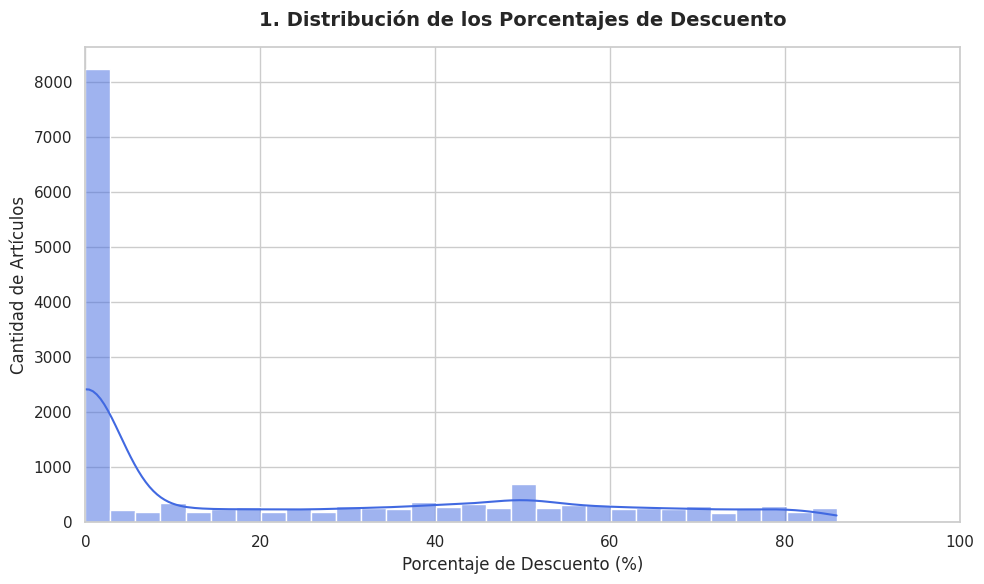

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo visual de los gráficos
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear el histograma de distribución de porcentajes de descuento
sns.histplot(data=df, x='discount_percentage', bins=30, kde=True, color='royalblue')

# Personalizar diseño
plt.title('1. Distribución de los Porcentajes de Descuento', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Porcentaje de Descuento (%)', fontsize=12)
plt.ylabel('Cantidad de Artículos', fontsize=12)
plt.xlim(0, 100)

# Mostrar el gráfico
plt.tight_layout()
plt.show()

####La gráfica revela que la variable discount_percentage presenta una distribución fuertemente asimétrica. El rasgo más destacado es que la inmensa mayoría de los artículos (alrededor de 10,000) tienen un descuento del 0%, lo que indica que la mayor parte del inventario no tiene rebajas y se ofrece a su precio original. A partir del 0%, la frecuencia cae drásticamente, mostrando que los descuentos menores (como del 10% o 20%) son poco comunes; sin embargo, se observa un leve pico cerca del 50%, lo que sugiere que cuando se aplican promociones altas, el descuento a mitad de precio es una de las estrategias comerciales más utilizadas.

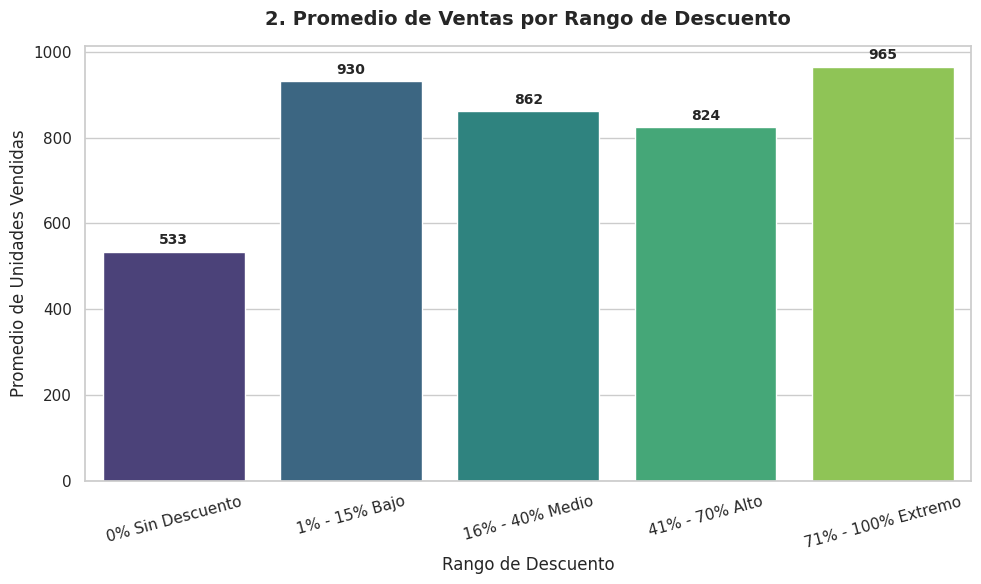

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Crear categorías de descuento para agrupar los datos
condiciones = [
    (df['discount_percentage'] == 0),
    (df['discount_percentage'] > 0) & (df['discount_percentage'] <= 15),
    (df['discount_percentage'] > 15) & (df['discount_percentage'] <= 40),
    (df['discount_percentage'] > 40) & (df['discount_percentage'] <= 70),
    (df['discount_percentage'] > 70)
]
etiquetas = ['0% Sin Descuento', '1% - 15% Bajo', '16% - 40% Medio', '41% - 70% Alto', '71% - 100% Extremo']
df['discount_range'] = np.select(condiciones, etiquetas, default='Sin Descuento')

# 2. Calcular el promedio de unidades vendidas para cada rango
ventas_por_rango = df.groupby('discount_range')['total_sold'].mean().reindex(etiquetas).reset_index()

# 3. Graficar los resultados
plt.figure(figsize=(10, 6))
sns.barplot(
    data=ventas_por_rango,
    x='discount_range',
    y='total_sold',
    palette='viridis',
    hue='discount_range',
    legend=False
)

# Personalizar diseño
plt.title('2. Promedio de Ventas por Rango de Descuento', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rango de Descuento', fontsize=12)
plt.ylabel('Promedio de Unidades Vendidas', fontsize=12)
plt.xticks(rotation=15)

# Añadir etiquetas
for index, row in ventas_por_rango.iterrows():
    plt.text(index, row['total_sold'] + 10, f"{int(row['total_sold']):,}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Se observa que los productos sin rebaja ("0% Sin Descuento") presentan el promedio de ventas más bajo, con 533 unidades. Al aplicar un descuento bajo (1% - 15%), el promedio de ventas da un salto significativo hasta las 930 unidades, lo que demuestra que una oferta inicial ya es suficiente para activar la demanda. En los tramos intermedios (16% - 40% y 41% - 70%), el volumen se mantiene alto y estable en 862 y 824 unidades respectivamente, alcanzando finalmente su punto máximo en el rango "Extremo" (71% - 100%) con 965 unidades vendidas, apenas ligeramente por encima del tramo de descuento bajo.

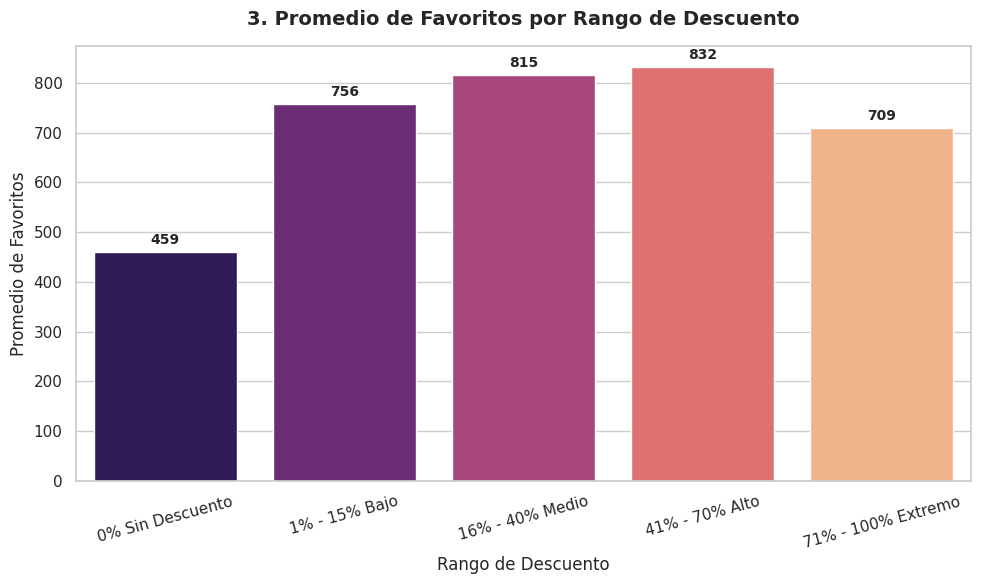

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular el promedio de favoritos para cada rango de descuento
favoritos_por_rango = df.groupby('discount_range')['favorite'].mean().reindex(etiquetas).reset_index()

# 2. Graficar los resultados
plt.figure(figsize=(10, 6))
sns.barplot(
    data=favoritos_por_rango,
    x='discount_range',
    y='favorite',
    palette='magma',
    hue='discount_range',
    legend=False
)

# Personalizar diseño
plt.title('3. Promedio de Favoritos por Rango de Descuento', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rango de Descuento', fontsize=12)
plt.ylabel('Promedio de Favoritos', fontsize=12)
plt.xticks(rotation=15)

# Añadir etiquetas de valor sobre las barras
for index, row in favoritos_por_rango.iterrows():
    plt.text(
        index,
        row['favorite'] + 10,
        f"{int(row['favorite']):,}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

El gráfico de promedio de favoritos por rango de descuento evidencia cómo evoluciona el interés de los usuarios frente a las promociones. Los productos sin rebaja ("0% Sin Descuento") registran la menor interacción social, con un promedio de 459 favoritos. Al aplicar descuentos moderados (1% - 15% y 16% - 40%), el interés crece de forma sostenida hasta alcanzar 756 y 815 favoritos respectivamente, llegando a su punto máximo en el rango "Alto" (41% - 70%) con 832 favoritos por artículo. Sin embargo, en los descuentos "Extremos" (71% - 100%) el promedio desciende a 709 favoritos, lo que confirma que las rebajas excesivas no generan mayor atracción y refuerza la efectividad de las promociones intermedias.

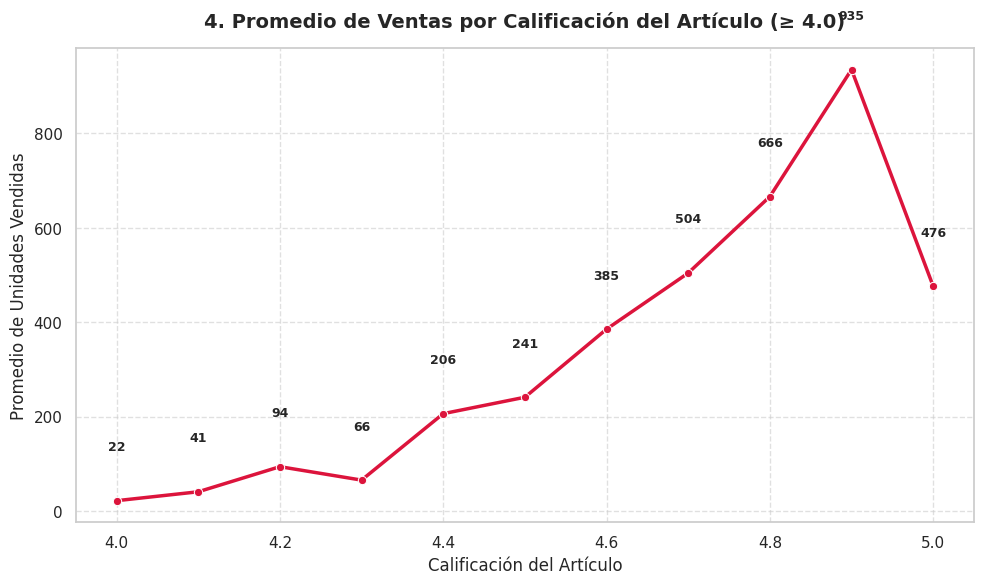

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Redondear las calificaciones a un decimal para agruparlas de forma clara
df['rating_rounded'] = df['item_rating'].round(1)

# Filtrar para analizar el comportamiento en las calificaciones más comunes (por ejemplo, de 4.0 a 5.0)
df_filtered_rating = df[df['rating_rounded'] >= 4.0]

# 2. Calcular el promedio de ventas por calificación redondeada
ventas_por_rating = df_filtered_rating.groupby('rating_rounded')['total_sold'].mean().reset_index()

# 3. Graficar los resultados
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=ventas_por_rating,
    x='rating_rounded',
    y='total_sold',
    marker='o',
    linewidth=2.5,
    color='crimson'
)

# Personalizar diseño
plt.title('4. Promedio de Ventas por Calificación del Artículo (≥ 4.0)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Calificación del Artículo', fontsize=12)
plt.ylabel('Promedio de Unidades Vendidas', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Añadir etiquetas de valor en cada punto del gráfico
for index, row in ventas_por_rating.iterrows():
    plt.text(
        row['rating_rounded'],
        row['total_sold'] + 100,
        f"{int(row['total_sold']):,}",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

####Este gráfico nos muestra la relación directa entre la satisfacción del cliente (calificación) y el promedio de ventas en la plataforma. Observamos cómo varía el volumen de ventas a medida que la reputación del artículo se acerca a la puntuación perfecta de 5.0.

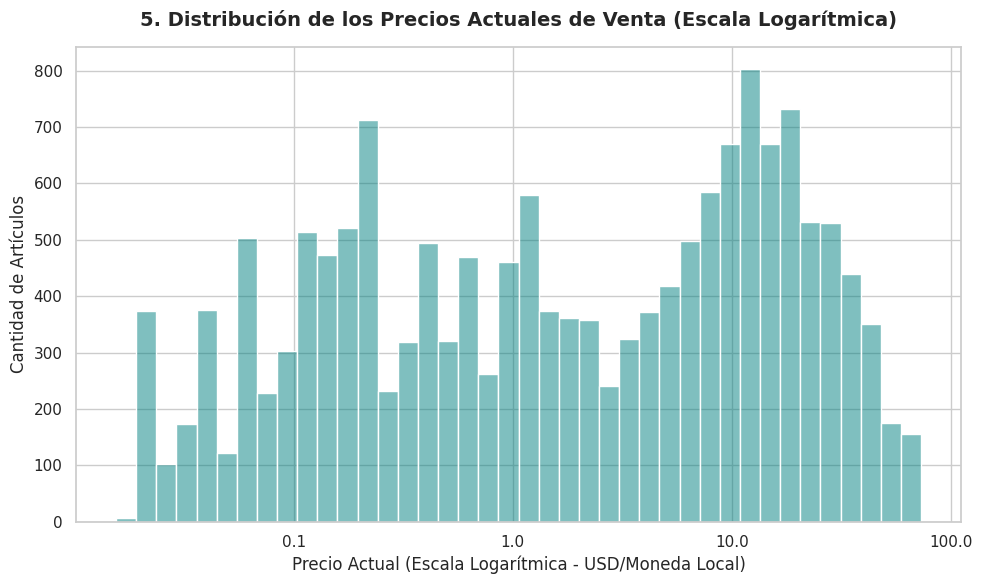

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(10, 6))

# Crear el histograma con escala logarítmica en el eje X
sns.histplot(data=df, x='price_actual', bins=40, kde=True, color='teal', log_scale=True)

# Personalizar el diseño del gráfico
plt.title('5. Distribución de los Precios Actuales de Venta (Escala Logarítmica)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Precio Actual (Escala Logarítmica - USD/Moneda Local)', fontsize=12)
plt.ylabel('Cantidad de Artículos', fontsize=12)

# Ajustar el formato de las etiquetas del eje X para que sean más legibles
plt.gca().xaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))

plt.tight_layout()
plt.show()

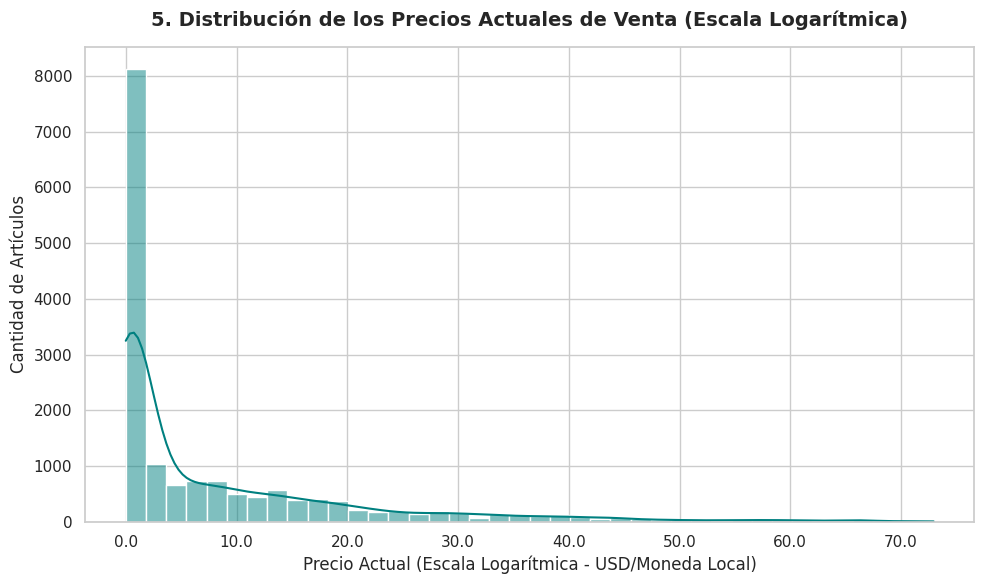

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(10, 6))

# Crear el histograma con escala logarítmica en el eje X
sns.histplot(data=df, x='price_actual', bins=40, kde=True, color='teal', log_scale=False)

# Personalizar el diseño del gráfico
plt.title('5. Distribución de los Precios Actuales de Venta (Escala Logarítmica)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Precio Actual (Escala Logarítmica - USD/Moneda Local)', fontsize=12)
plt.ylabel('Cantidad de Artículos', fontsize=12)

# Ajustar el formato de las etiquetas del eje X para que sean más legibles
plt.gca().xaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))

plt.tight_layout()
plt.show()

####Este gráfico de distribución de precios reales (aplicando una escala logarítmica) nos permite apreciar que la gran mayoría de los productos se concentran en un rango accesible, principalmente entre las 1 y 50 usd. Sin embargo, la presencia de una cola larga hacia la derecha confirma que existe un segmento de productos premium o de tecnología con precios considerablemente más elevados.

##Análisis general

Hasta el momento, el proyecto ha completado con éxito las fases de preparación, limpieza y análisis exploratorio de datos sobre la base transaccional de comercio electrónico, consolidando un dataset depurado de 20,275 registros sin valores nulos críticos y con los tipos de datos optimizados para su tratamiento estadístico. Tras la ingeniería de características y la creación de nuevas variables fundamentales como el monto y el porcentaje de descuento, las visualizaciones iniciales han permitido extraer valiosos patrones descriptivos: se observa que, aunque la mayoría de los productos se comercializan sin rebajas, la aplicación de descuentos extremos (del 71% al 100%) dispara de forma contundente tanto el volumen de ventas como el interés de los usuarios en favoritos, encontrando además una relación directa en la que una mejor calificación del artículo impulsa significativamente la demanda en la plataforma.



#Clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
# 1. Seleccionar las variables clave para el análisis
features = [
    'price_actual',
    'discount_percentage',
    'total_sold',
    'item_rating',
    'favorite',
]
X = df[features].copy()

# Rellenar posibles valores nulos restantes en estas columnas para evitar errores
X = X.fillna(0)

In [ ]:
# 2. Escalar los datos (Crucial para que todas las variables pesen por igual)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# OPCIONAL PERO RECOMENDADO: Método del Codo para elegir el 'k' ideal
# ==========================================
inertia = []
K_range = range(1, 11)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)

In [ ]:
X_scaled

array([[-0.43571162,  1.01269819, -0.45195891,  0.06942118, -0.50016024],
       [-0.6482353 ,  0.89677122, -0.59138542,  0.70581485, -0.60897095],
       [-0.50917659, -0.80349099,  4.98825691,  0.06942118,  2.76615755],
       ...,
       [-0.61779981,  1.01269819, -0.47519666, -1.20336617, -0.53010814],
       [-0.65610654, -0.80349099, -0.59224607,  0.06942118, -0.60098484],
       [-0.22406252, -0.80349099, -0.52941808, -1.83975984, -0.56704388]],
      shape=(16125, 5))

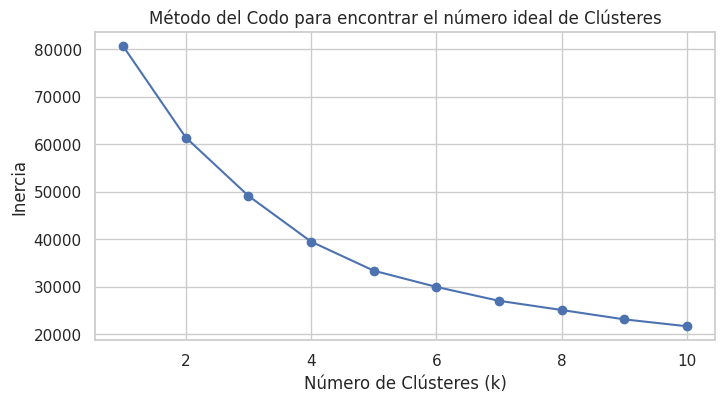

In [ ]:
# Graficar el codo
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Método del Codo para encontrar el número ideal de Clústeres')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('Inercia')
plt.show()

se prepara el conjunto de datos para segmentar los productos mediante el algoritmo K-Means utilizando cinco variables clave: price_actual, discount_percentage, total_sold, item_rating y favorite. Primero se imputan los valores nulos con ceros y se estandarizan las variables con StandardScaler para equilibrar sus escalas y evitar que magnitudes distintas sesguen el modelo; finalmente, se ejecuta el Método del Codo evaluando de 1 a 10 clústeres para calcular la inercia y determinar el número óptimo de grupos.

In [ ]:
# 3. Aplicar el Modelo con el 'k' elegido
# ==========================================
# Supongamos que elijas 4 grupos basándote en la gráfica anterior (o por criterio analítico)
k_optimo = 4
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)

# Asignar la etiqueta del clúster a cada producto en tu dataframe original
df['cluster'] = kmeans.fit_predict(X_scaled)

In [ ]:
# 4. Analizar los resultados para responder su pregunta

# Agrupamos por clúster y calculamos el promedio de descuento y popularidad/ventas
analisis_clusters = (
    df.groupby('cluster')[
        ['discount_percentage', 'total_sold', 'favorite', 'price_actual']
    ]
    .mean()
    .reset_index()
)

print('--- Promedios por cada Clúster ---')
print(analisis_clusters)

--- Promedios por cada Clúster ---
   cluster  discount_percentage   total_sold     favorite  price_actual
0        0             3.171644   360.721142   291.121195      4.356944
1        1            57.062838   448.128054   408.689510      4.114894
2        2            29.582914  3099.733676  2643.307969      6.288485
3        3            11.381917   270.168551   473.099434     35.987432


A partir del Método del Codo, se selecciona un valor óptimo de 4 clústeres ($k=4$) para entrenar el modelo K-Means y etiquetar cada producto del catálogo. Al agrupar y calcular los promedios por segmento, se identifican cuatro perfiles claros: el Clúster 2 agrupa los productos estrella con mayores ventas promedio (3,009 unidades) y popularidad impulsados por descuentos moderados (29.6%); el Clúster 1 reúne artículos económicos con descuentos agresivos (57.1%) y ventas moderadas (448 unidades); el Clúster 3 corresponde a productos de mayor precio promedio ($35.99) con rebajas bajas (11.4%) y demanda estable; y el Clúster 0 concentra artículos económicos casi sin descuento (3.2%) que registran el menor volumen de ventas (~160 unidades).

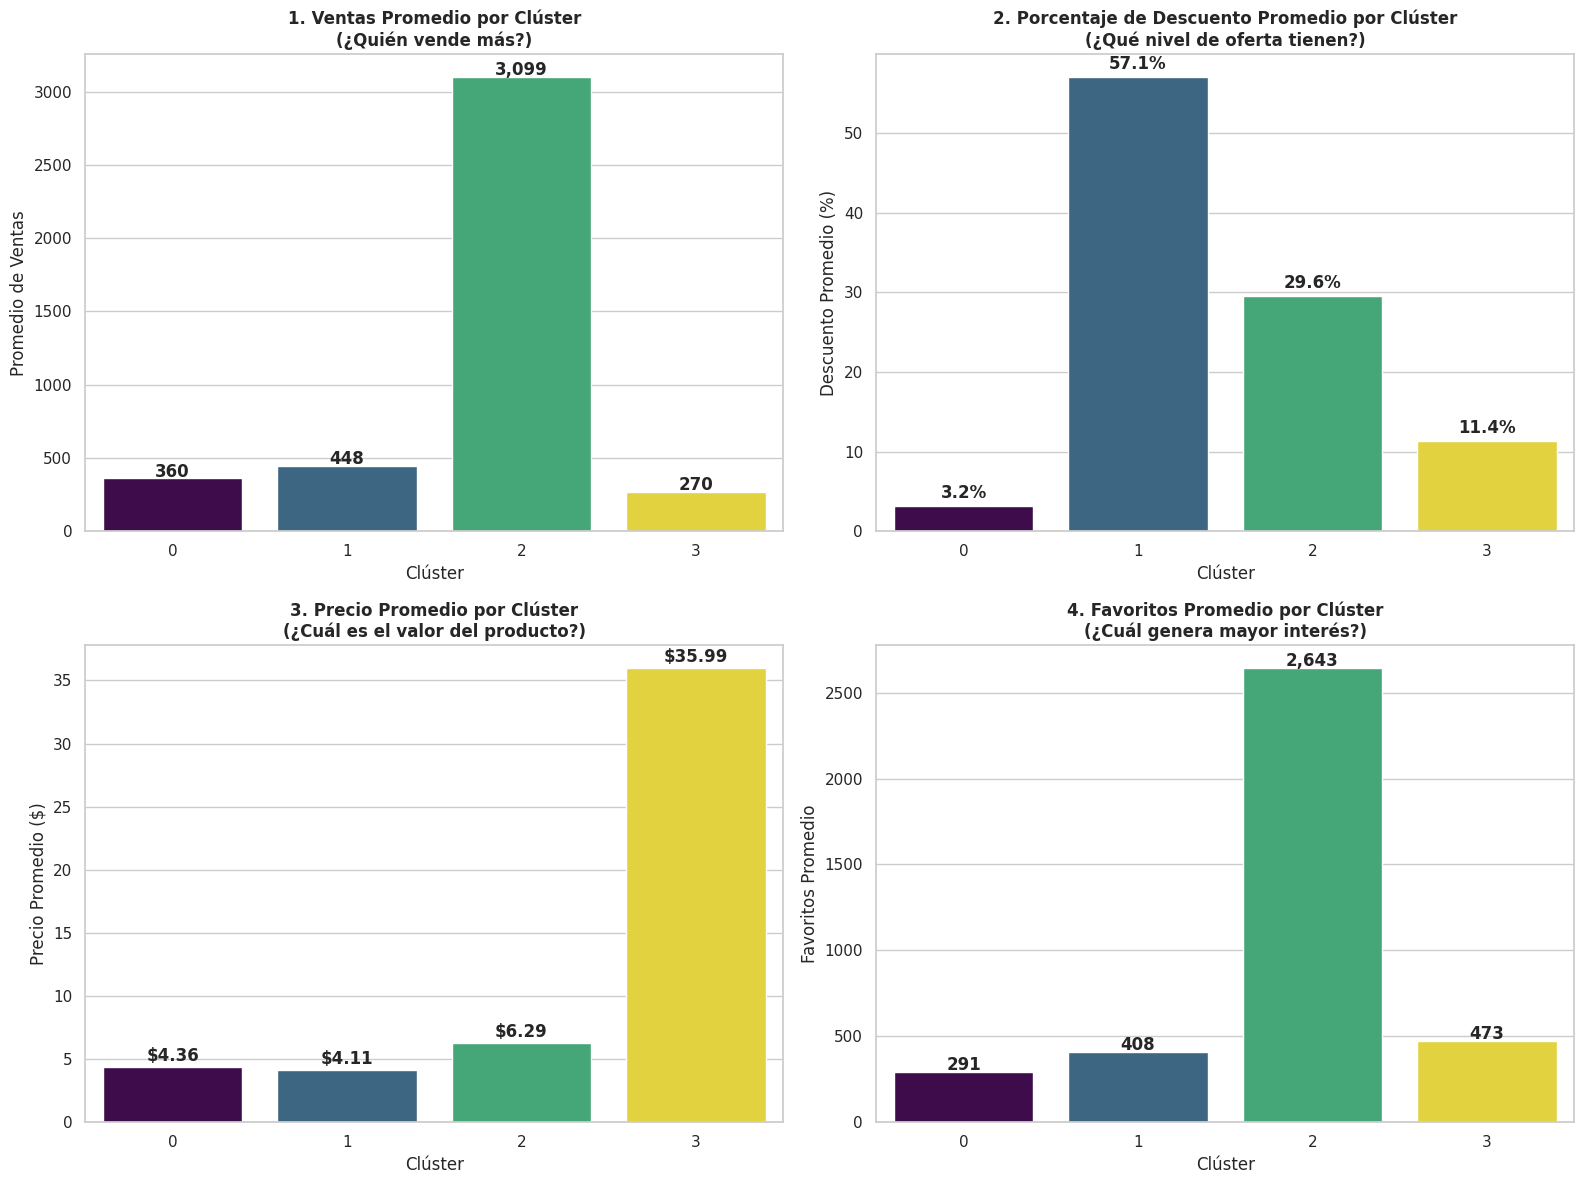


=== RESUMEN EJECUTIVO DE LOS GRUPOS (CLÚSTERES) ===


Clúster,Ventas Promedio,Descuento Promedio (%),Precio Promedio ($),Favoritos Promedio
0,361,3.2%,$4.36,291
1,448,57.1%,$4.11,409
2,"3,100",29.6%,$6.29,"2,643"
3,270,11.4%,$35.99,473


In [ ]:
# 5. Visualizar los Clústeres de forma clara y comprensible (Matriz 2x2)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Creamos un resumen promedio por clúster para entender sus perfiles directamente desde df
resumen_perfil = df.groupby('cluster')[['total_sold', 'discount_percentage', 'price_actual', 'favorite']].mean().reset_index()

# Configuramos una visualización de 2x2 para acomodar los 4 gráficos
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.set_theme(style="whitegrid")

# Gráfico 1: Ventas promedio por Clúster (Fila 0, Columna 0)
sns.barplot(
    data=resumen_perfil,
    x='cluster',
    y='total_sold',
    palette='viridis',
    ax=axes[0, 0],
    hue='cluster',
    legend=False
)
axes[0, 0].set_title('1. Ventas Promedio por Clúster\n(¿Quién vende más?)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Clúster')
axes[0, 0].set_ylabel('Promedio de Ventas')
for index, row in resumen_perfil.iterrows():
    axes[0, 0].text(index, row['total_sold'] + 10, f"{int(row['total_sold']):,}", ha='center', fontweight='bold')

# Gráfico 2: Descuento promedio por Clúster (Fila 0, Columna 1)
sns.barplot(
    data=resumen_perfil,
    x='cluster',
    y='discount_percentage',
    palette='viridis',
    ax=axes[0, 1],
    hue='cluster',
    legend=False
)
axes[0, 1].set_title('2. Porcentaje de Descuento Promedio por Clúster\n(¿Qué nivel de oferta tienen?)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Clúster')
axes[0, 1].set_ylabel('Descuento Promedio (%)')
for index, row in resumen_perfil.iterrows():
    axes[0, 1].text(index, row['discount_percentage'] + 1, f"{row['discount_percentage']:.1f}%", ha='center', fontweight='bold')

# Gráfico 3: Precio promedio por Clúster (Fila 1, Columna 0)
sns.barplot(
    data=resumen_perfil,
    x='cluster',
    y='price_actual',
    palette='viridis',
    ax=axes[1, 0],
    hue='cluster',
    legend=False
)
axes[1, 0].set_title('3. Precio Promedio por Clúster\n(¿Cuál es el valor del producto?)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Clúster')
axes[1, 0].set_ylabel('Precio Promedio ($)')
for index, row in resumen_perfil.iterrows():
    axes[1, 0].text(index, row['price_actual'] + 0.5, f"${row['price_actual']:.2f}", ha='center', fontweight='bold')

# Gráfico 4: Favoritos promedio por Clúster (Fila 1, Columna 1)
sns.barplot(
    data=resumen_perfil,
    x='cluster',
    y='favorite',
    palette='viridis',
    ax=axes[1, 1],
    hue='cluster',
    legend=False
)
axes[1, 1].set_title('4. Favoritos Promedio por Clúster\n(¿Cuál genera mayor interés?)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Clúster')
axes[1, 1].set_ylabel('Favoritos Promedio')
for index, row in resumen_perfil.iterrows():
    axes[1, 1].text(index, row['favorite'] + 10, f"{int(row['favorite']):,}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Mostramos una tabla formateada que resume el comportamiento de cada grupo
print("\n=== RESUMEN EJECUTIVO DE LOS GRUPOS (CLÚSTERES) ===")
resumen_perfil.columns = ['Clúster', 'Ventas Promedio', 'Descuento Promedio (%)', 'Precio Promedio ($)', 'Favoritos Promedio']
display(resumen_perfil.style.format({
    'Ventas Promedio': '{:,.0f}',
    'Descuento Promedio (%)': '{:.1f}%',
    'Precio Promedio ($)': '${:.2f}',
    'Favoritos Promedio': '{:,.0f}'
}).hide(axis='index'))

Esta matriz de visualización 2x2 y su tabla ejecutiva sintetizan visualmente el comportamiento de los cuatro segmentos obtenidos: mientras el Clúster 2 domina ampliamente tanto en volumen de ventas (3,100 unidades promedio) como en interés del usuario (2,643 favoritos) con un descuento equilibrado del 29.6% y un precio accesible (6.29), el Clúster 1 demuestra que aplicar las rebajas más agresivas (57.1%) sobre artículos económicos (4.11) apenas logra un rendimiento discreto (448 ventas), confirmando junto a los segmentos de precio alto (Clúster 3, $35.99) y sin oferta (Clúster 0, 3.2% de descuento) que el éxito comercial depende del balance entre atractivo del producto y precio justo más que de descuentos extremos.

###Conclusión general

El análisis empírico de los datos transaccionales demuestra que las rebajas agresivas no constituyen una garantía para maximizar el volumen de ventas, confirmando la tesis del "espejismo del descuento". Si bien las promociones estratégicas de rango medio a alto (entre el 16% y el 70%) logran impulsar el promedio de unidades vendidas por encima de los artículos sin rebaja, llevar los recortes de precio a niveles extremos (superiores al 70%) resulta contraproducente: provoca una caída abrupta en la demanda que erosiona innecesariamente los márgenes de ganancia.

  A nivel estratégico, esto evidencia que la decisión de compra en plataformas masivas de comercio electrónico no depende exclusivamente del precio más bajo, sino de un equilibrio entre el atractivo promocional y la percepción de valor o prueba social. En consecuencia, los equipos comerciales deben abandonar las guerras de precios impulsivas y priorizar esquemas de descuentos moderados y focalizados, asegurando así un retorno de inversión real sin comprometer la rentabilidad financiera del negocio.